# Plot trends

In [1]:
source('/projects/code/maap_tools/lib/plot_trends.r')


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


terra 1.7.78


Attaching package: ‘terra’


The following object is masked from ‘package:scales’:

    rescale


The following object is masked from ‘package:tidyr’:

    extract


Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE

Loading required package: abind



Reading raster files...
Processing 8120292 valid pixels...


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'α=0.05' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'α=0.05' in 'mbcsToSbcs': dot substituted for <b1>”


Summary statistics figure saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0002844_10yrs_ols_summary_statistics_R.png 

KENDALL'S TAU SUMMARY STATISTICS
Total valid pixels: 8120292 
Mean τ: -0.1175 
Median τ: -0.1556 
Range: [-1, 1]
Significant pixels (p<0.05): 1461450 (18%)


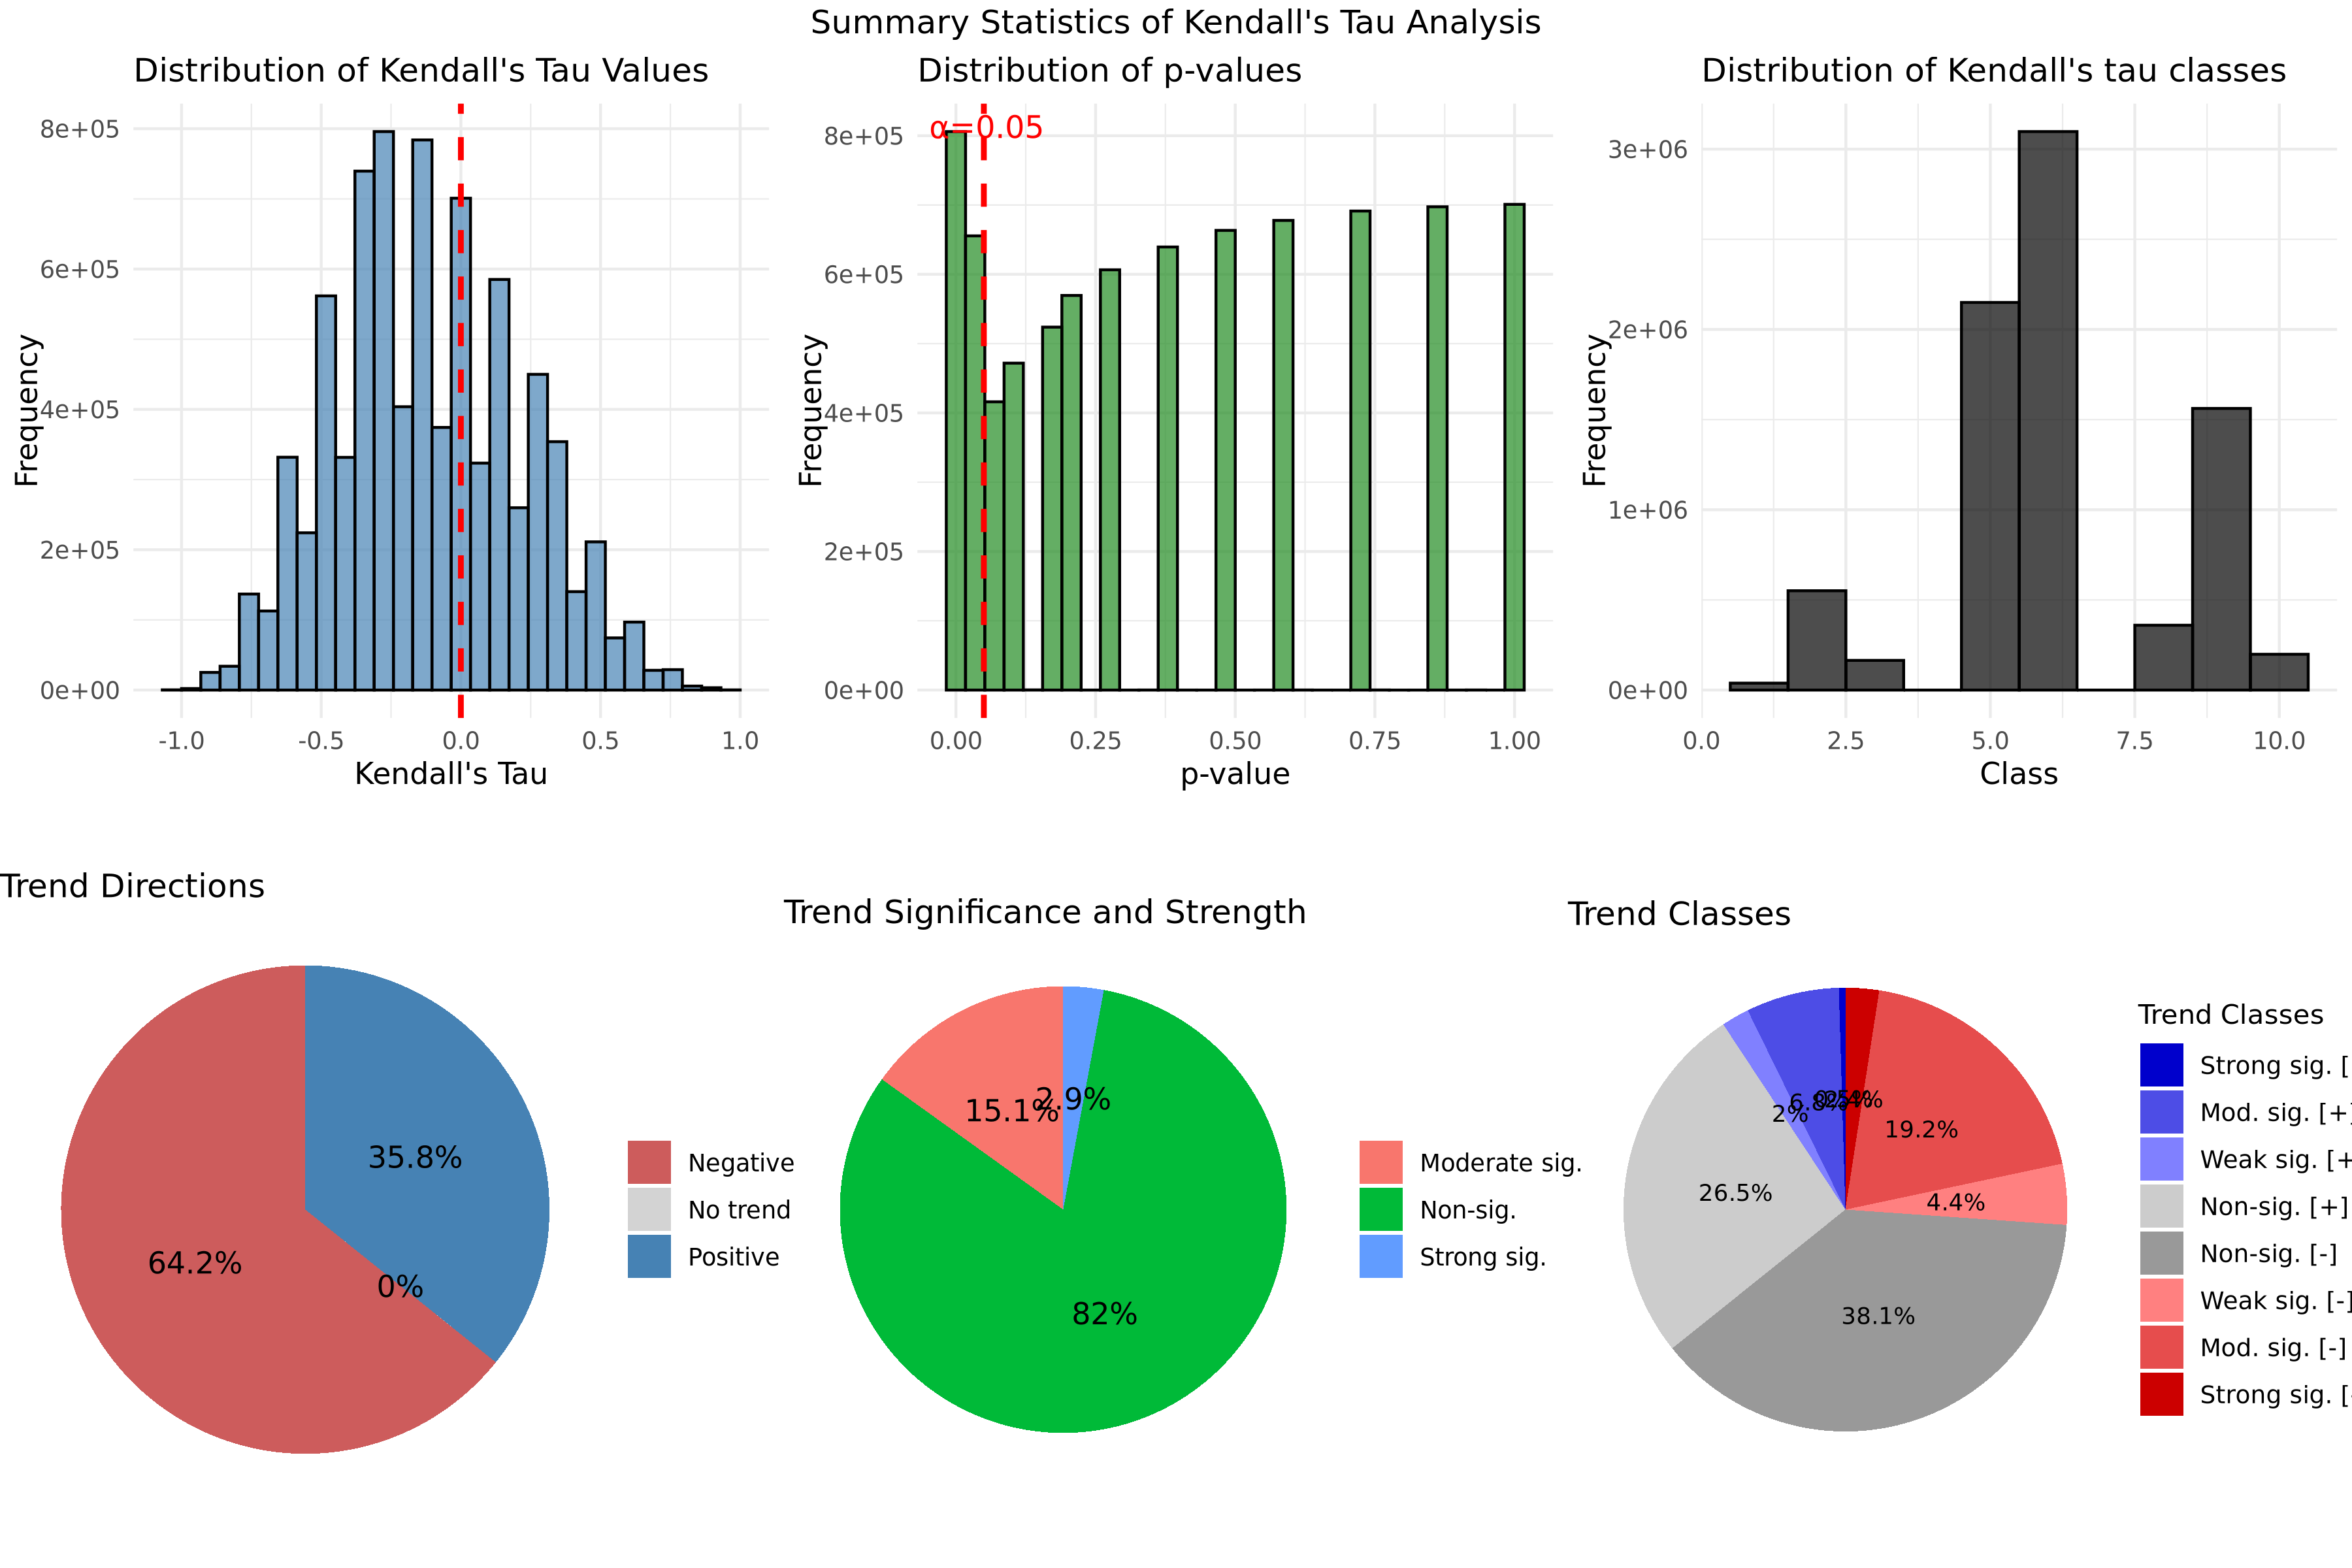

In [3]:
options(repr.plot.width =12, repr.plot.height = 8, repr.plot.res = 300)

FOCAL_TILE = 2844
FILE_STEM = paste0("/projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_", sprintf("%07d", FOCAL_TILE),"_10yrs_ols")

# Create summary statistics from raster files
summary_plot <- create_summary_statistics_figure(
  raster_path = paste0(FILE_STEM, '.tif'),
  class_raster_path = paste0(FILE_STEM, '_kendallclasses.tif'),
  output_path = paste0(FILE_STEM, "_summary_statistics_R.png"),
  alpha = 0.05
)

Reading classified raster file...
Simple feature collection with 6 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: 2888522 ymin: 3753274 xmax: 2889002 ymax: 3753304
Projected CRS: unnamed
  class                       geometry
1     6 POLYGON ((2888522 3753304, ...
2     5 POLYGON ((2888552 3753304, ...
3     8 POLYGON ((2888762 3753304, ...
4     6 POLYGON ((2888882 3753304, ...
5     8 POLYGON ((2888912 3753304, ...
6     5 POLYGON ((2888972 3753304, ...
Plotting 1670902 valid pixels...
Classified map saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_multiyear_atl08v6/boreal_agb_trends_0002844_10yrs_ols_classified_map_R.png 


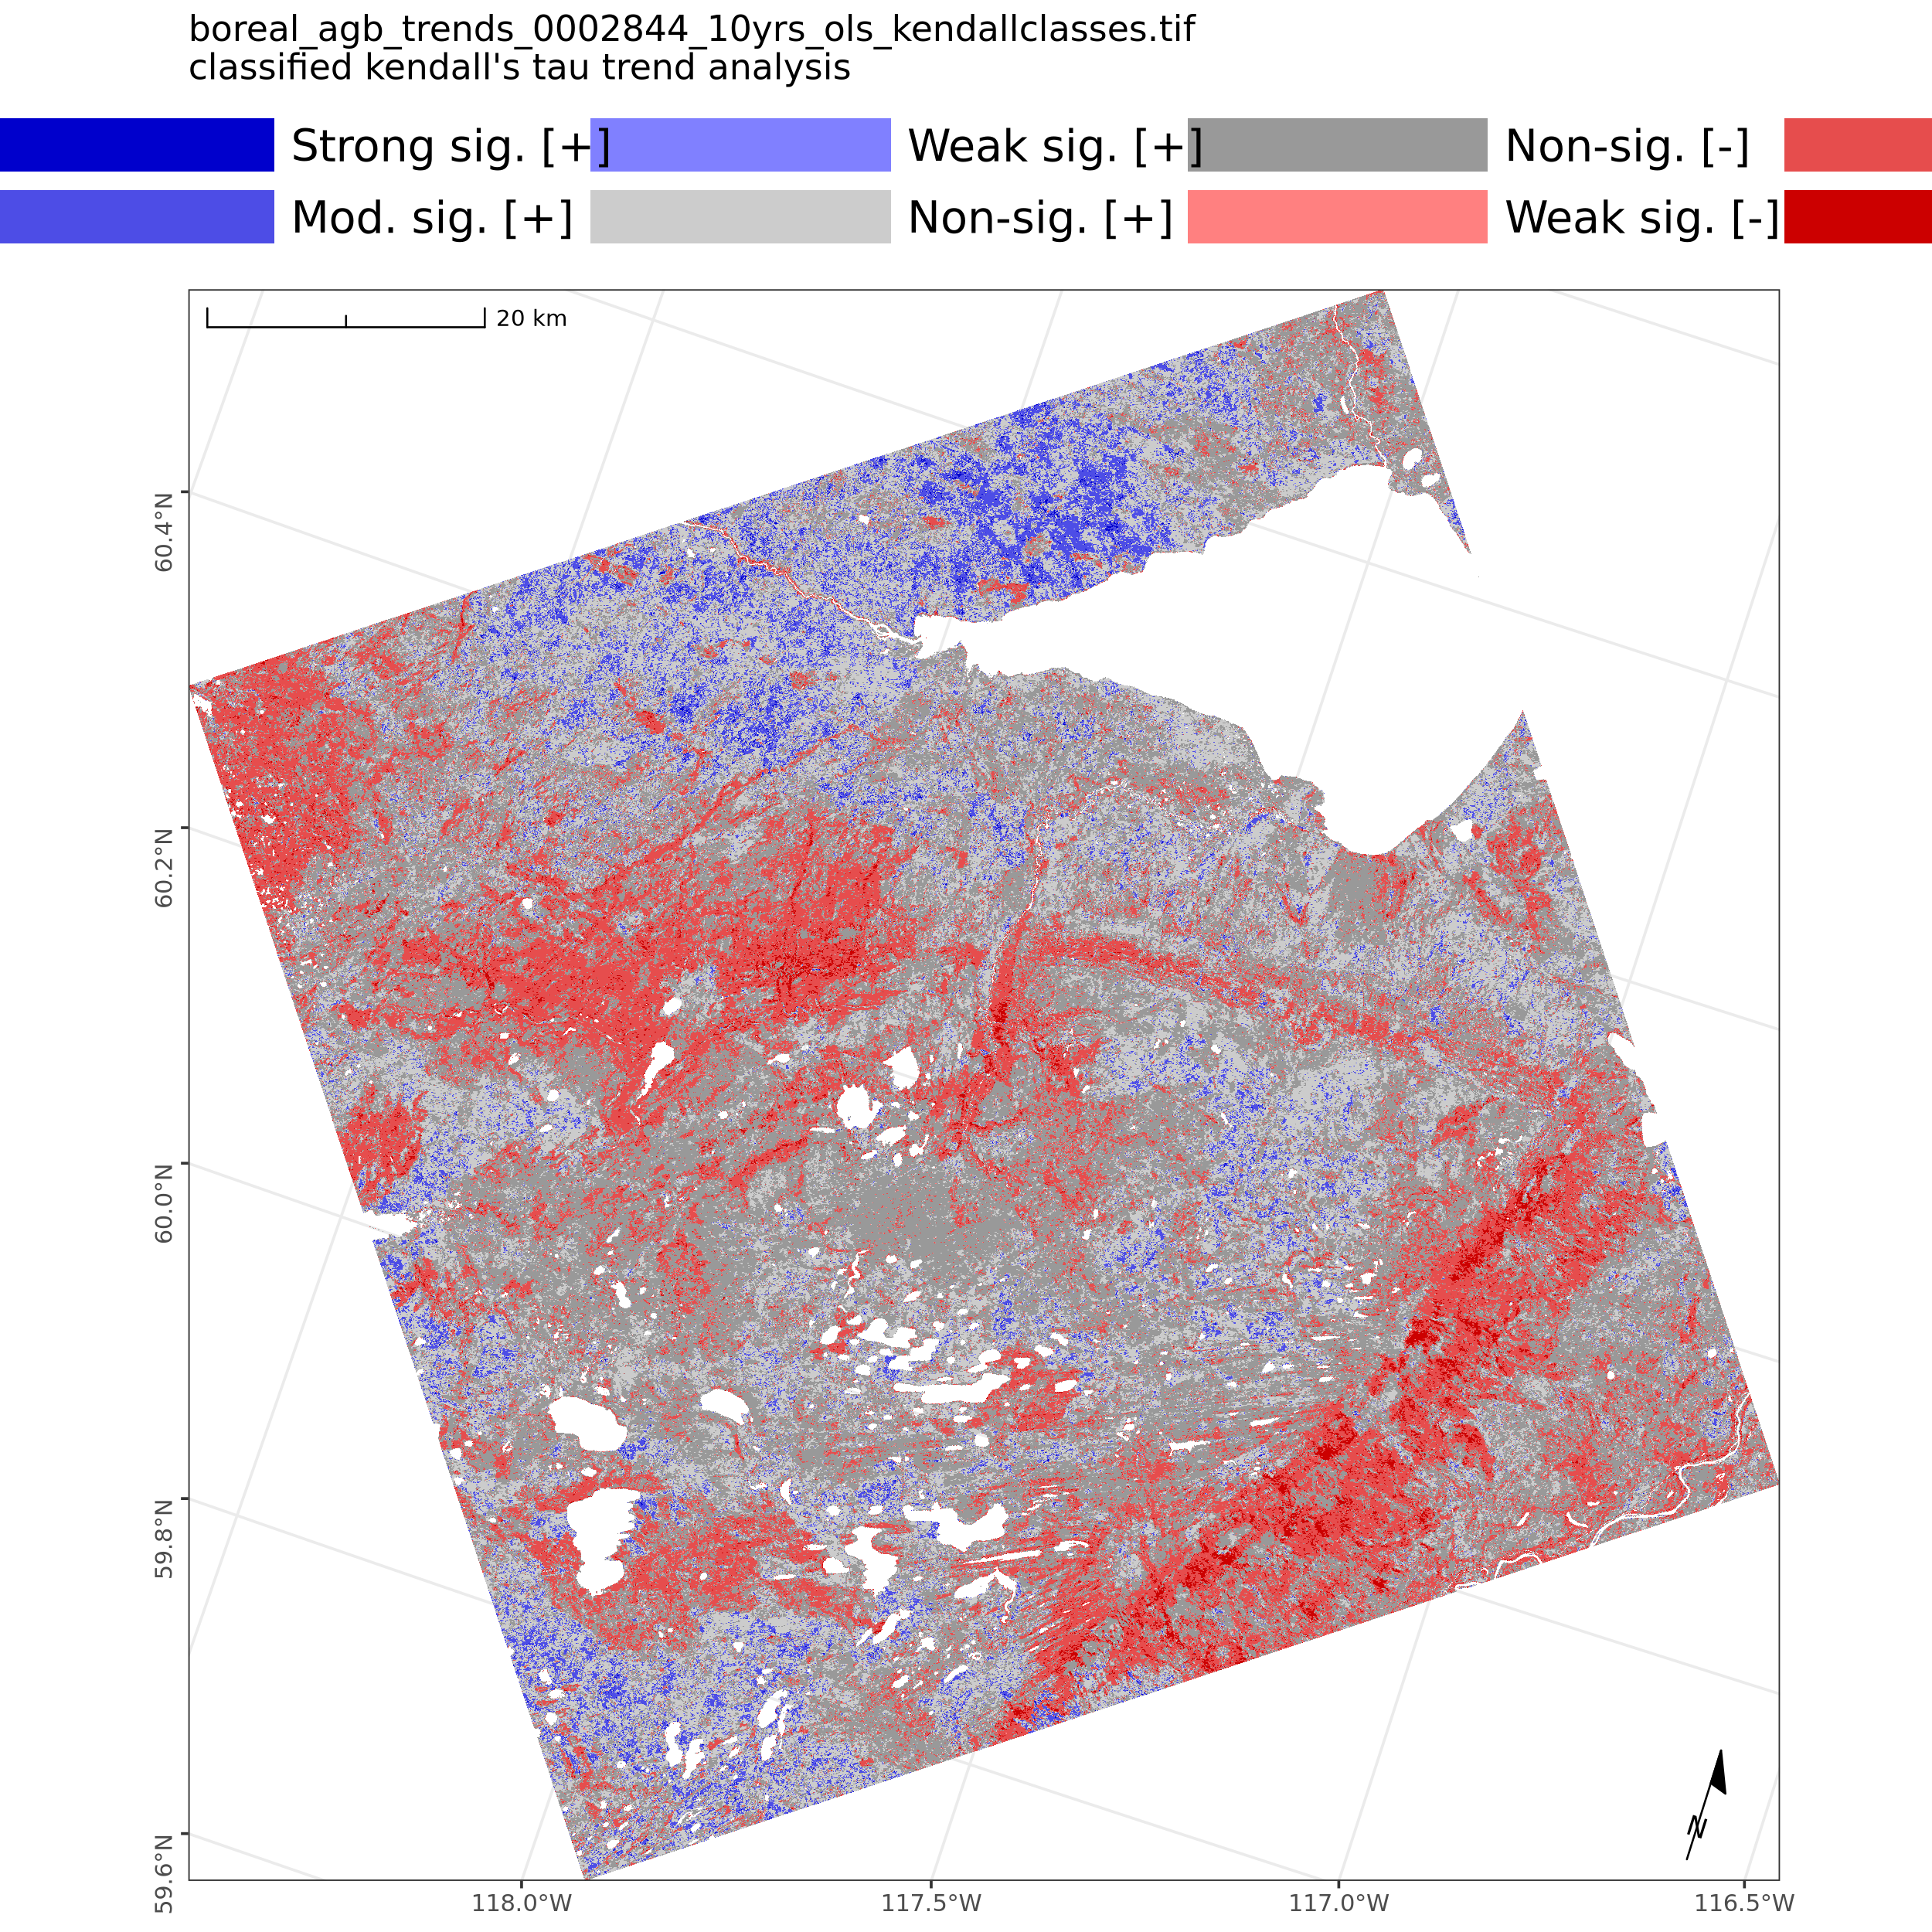

In [4]:
options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 250)

# Create classified map from raster file
map_plot <- plot_classified_kendall_map(
  class_raster_path = paste0(FILE_STEM, '_kendallclasses.tif'),
  output_path = paste0(FILE_STEM, "_classified_map_R.png")
)

In [1]:
FOCAL_TILE = 475
FILE_STEM = paste0("/projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_", sprintf("%07d", FOCAL_TILE))

Reading raster files...
Processing 8844502 valid pixels...


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'α=0.05' in 'mbcsToSbcs': dot substituted for <ce>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'α=0.05' in 'mbcsToSbcs': dot substituted for <b1>”


Summary statistics figure saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0000518_summary_statistics_R.png 

KENDALL'S TAU SUMMARY STATISTICS
Total valid pixels: 8844502 
Mean τ: 0.2841 
Median τ: 0.3333 
Range: [-1, 1]
Significant pixels (p<0.05): 408994 (4.6%)


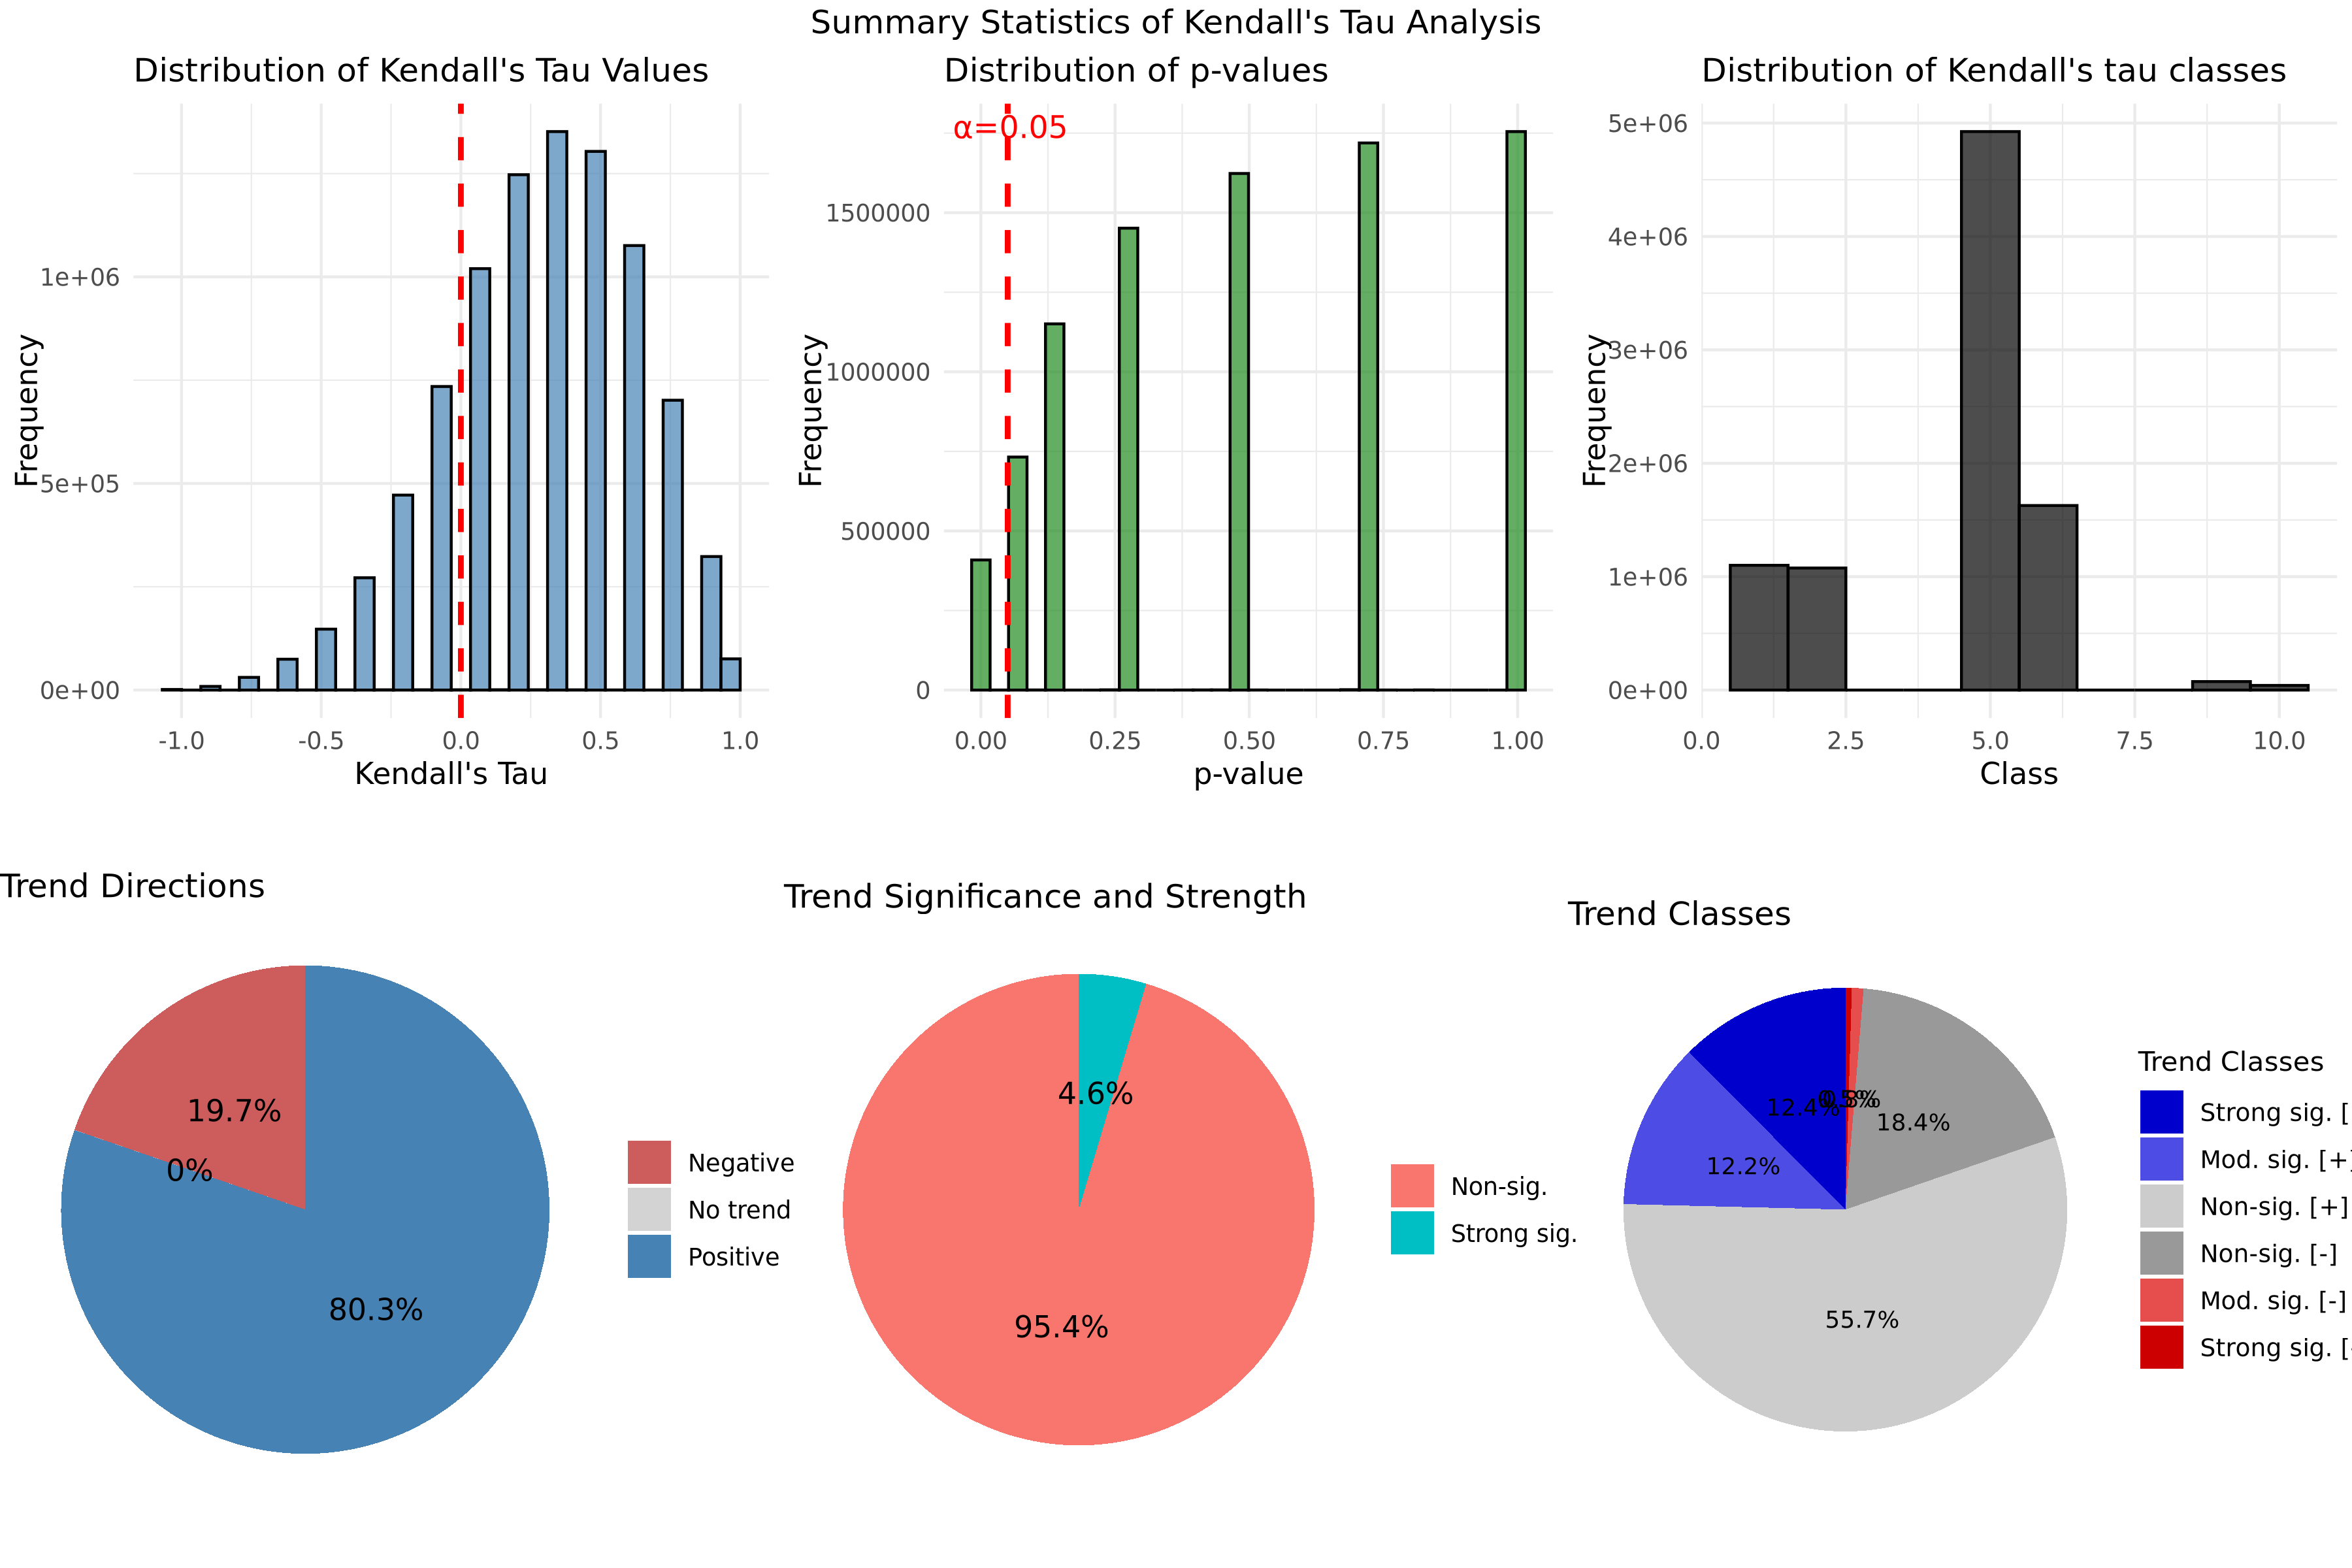

In [10]:
options(repr.plot.width =12, repr.plot.height = 8, repr.plot.res = 300)

# Install required packages if not already installed
# install.packages(c("ggplot2", "dplyr", "tidyr", "gridExtra", "scales", "terra"))

# Create summary statistics from raster files
summary_plot <- create_summary_statistics_figure(
  tau_raster_path = paste0(FILE_STEM, "_kendall_tau.tif"),
  p_raster_path = paste0(FILE_STEM, "_kendall_p.tif"), 
  class_raster_path = paste0(FILE_STEM, "_trend_kendall_tau_categorical.tif"),
  output_path = paste0(FILE_STEM, "_summary_statistics_R.png"),
  alpha = 0.05
)


In [16]:
library(terra)
class_raster <- terra::rast(paste0(FILE_STEM, "_trend_kendall_tau_categorical.tif"))

In [17]:
class_raster

class       : SpatRaster 
dimensions  : 3000, 3000, 1  (nrow, ncol, nlyr)
resolution  : 30, 30  (x, y)
extent      : 1448522, 1538522, 3033304, 3123304  (xmin, xmax, ymin, ymax)
coord. ref. : +proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +ellps=GRS80 +towgs84=0,0,0,0,0,0,0 +units=m +no_defs 
source      : boreal_ht_trends_0003458_trend_kendall_tau_categorical.tif 
name        : boreal_ht_trends_0003458_trend_kendall_tau_categorical 
min value   :                                                      0 
max value   :                                                     10 

In [49]:
source('/projects/code/maap_tools/lib/plot_trends.r')

Reading classified raster file...
Simple feature collection with 6 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -3321478 ymin: 7173274 xmax: -3321118 ymax: 7173304
Projected CRS: unnamed
  class                       geometry
1     5 POLYGON ((-3321478 7173304,...
2     6 POLYGON ((-3321448 7173304,...
3     2 POLYGON ((-3321298 7173304,...
4     2 POLYGON ((-3321208 7173304,...
5     1 POLYGON ((-3321178 7173304,...
6     2 POLYGON ((-3321148 7173304,...
Plotting 2004868 valid pixels...
Classified map saved to: /projects/my-public-bucket/local_output/compute_trends/full_run_niter30_singleyear_atl08v6/boreal_agb_trends_0000518_classified_map_R.png 


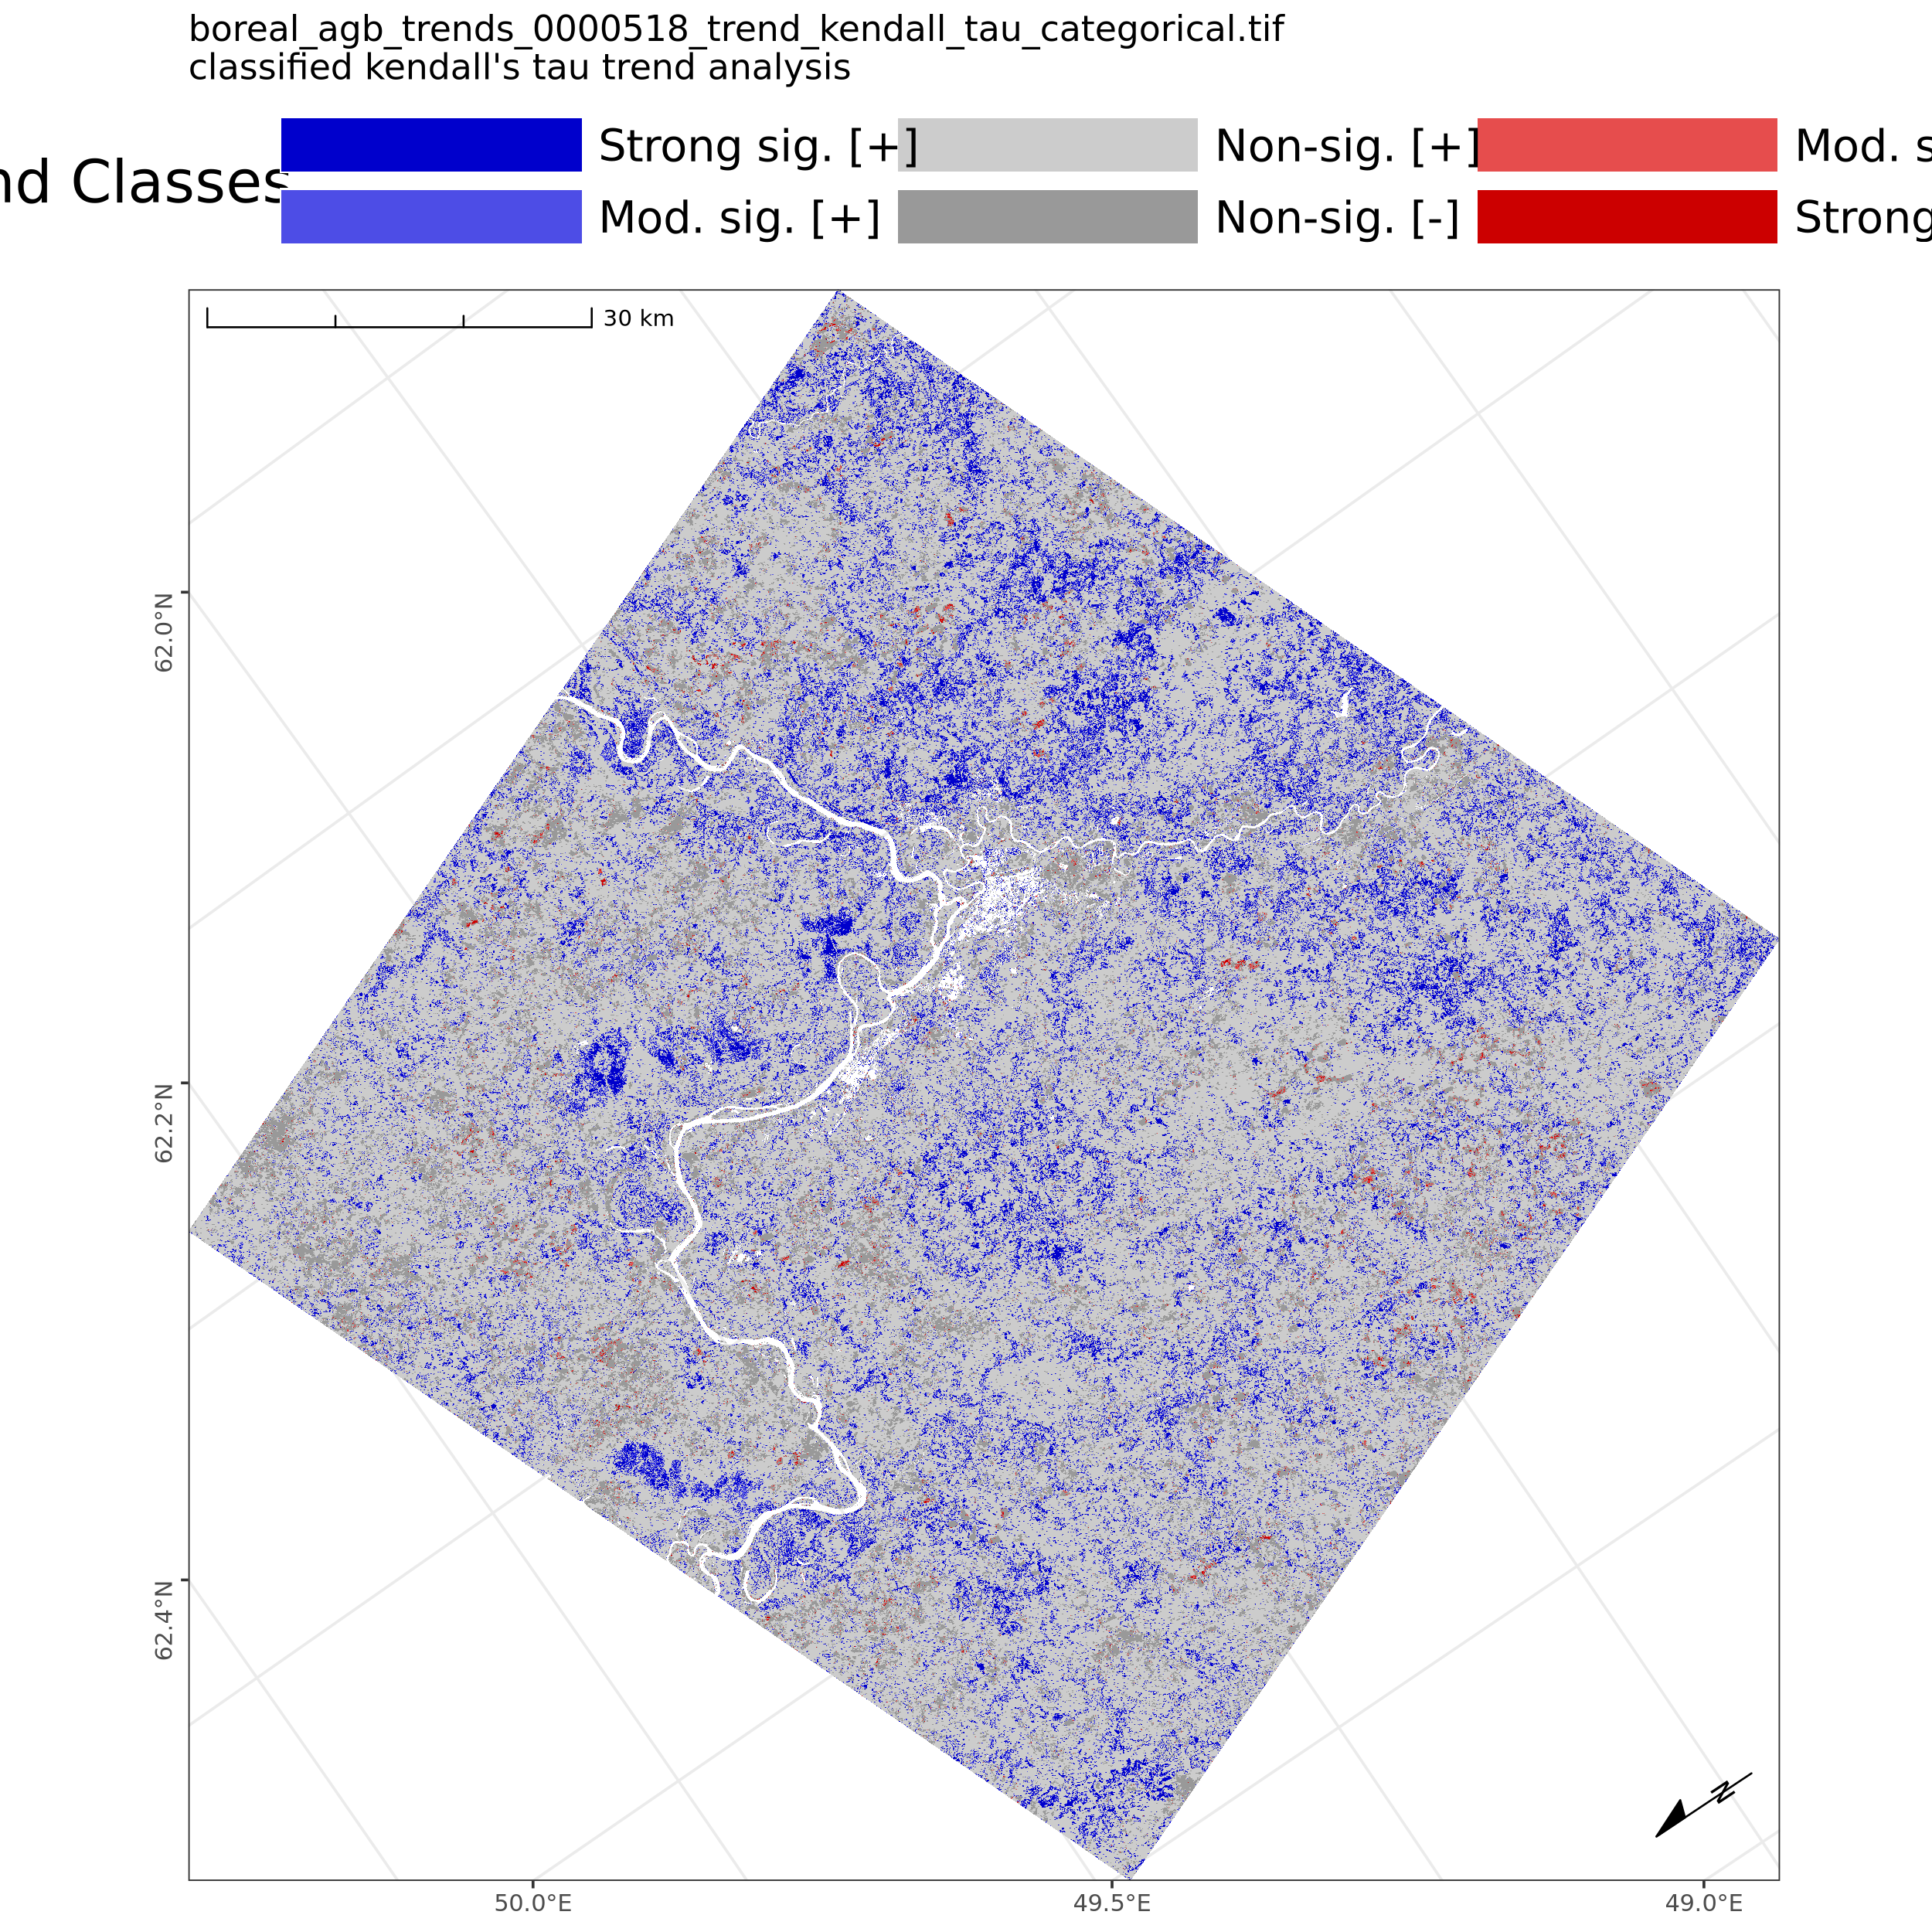

In [5]:
options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 250)

# Create classified map from raster file
map_plot <- plot_classified_kendall_map(
  class_raster_path = paste0(FILE_STEM, "_trend_kendall_tau_categorical.tif"),
  output_path = paste0(FILE_STEM, "_classified_map_R.png")
)
